# Evaluación ampliada — validación cruzada, AUC, calibración y bootstrap por bloques

**Objetivo.** Completar la evaluación de `04_modelo.ipynb` con las métricas y los controles que faltaban:

1. **Validación cruzada:** comparar el esquema temporal (el que usamos) con los esquemas habituales (K-fold aleatorio, *leave-one-season-out*) para medir cuánto se equivocaría un esquema ingenuo.
2. **Curvas ROC y AUC** por resultado (H, D, A) y macro, por fold y agregadas, con intervalos.
3. **Calibración:** ECE (barras de igual ancho e igual masa), MCE, Brier, pendiente e intercepto, diagramas de fiabilidad por resultado, y recalibración posterior (*temperature / vector scaling*).
4. **Matrices de confusión** y métricas por clase.
5. **Bootstrap por bloques** (semana de calendario) en lugar de bootstrap de partidos sueltos, y **corrección de Benjamini–Hochberg** sobre todas las comparaciones.

**Entrada.** `modelos_oof.csv` (predicciones fuera de muestra de los 8 folds, generadas en `04_modelo.ipynb`, Paso 7), `dataset_final.csv`, `backtest_odds.csv`, `feature_sets.json`, `hiperparametros*.json`.

**Convención.** Cada celda de código va precedida por una celda de texto (qué vamos a hacer y por qué) y seguida por otra (qué encontramos y qué decidimos).

**Referencias.** James et al. (ISLP) cap. 4 (curvas ROC, matriz de confusión), cap. 5 (validación cruzada y *bootstrap*) y cap. 13 (FDR); Siddiqi cap. 10 (KS, AUC/c-stat) y cap. 12 (estabilidad).

## Paso 0 — Carga y definición de bloques

**Qué vamos a hacer.** Cargar las predicciones fuera de muestra de los ocho modelos y definir los **bloques** del bootstrap: cada partido pertenece a un bloque `(temporada, semana ISO)`.

**Por qué.** Los partidos de la misma semana comparten contexto (clima, calendario, el mismo ajuste del mercado) y los de una misma temporada comparten ritmo de juego. Remuestrear partidos sueltos supone independencia y da intervalos demasiado estrechos; remuestrear **bloques** respeta esa dependencia.

In [1]:
import json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (log_loss, accuracy_score, balanced_accuracy_score, roc_auc_score, roc_curve,
                             confusion_matrix, precision_recall_fscore_support)

warnings.filterwarnings('ignore')
DATA = '../data/'
df = pd.read_csv(DATA + 'dataset_final.csv')
odds = pd.read_csv(DATA + 'backtest_odds.csv')
fs = json.load(open(DATA + 'feature_sets.json'))
HP = json.load(open(DATA + 'hiperparametros.json'))
oo = pd.read_csv(DATA + 'modelos_oof.csv')

NOMBRES = ['prior', 'mercado', 'LR (cuotas)', 'HGB (F1)', 'XGBoost (F2)', 'SVM (F1)', 'MLP (F1)', 'ALL (promedio)']
P = {n: oo[[f'{n}|{l}' for l in 'HDA']].to_numpy() for n in NOMBRES}
y = oo['y'].to_numpy()
fold = oo['fold'].to_numpy()
FOLDS = sorted(np.unique(fold))

fechas = pd.to_datetime(df['Date'], dayfirst=True, format='mixed')
sem = fechas.dt.isocalendar().week.to_numpy()
bloque_full = pd.factorize(df['Season'].astype(str) + '-' + pd.Series(sem).astype(str))[0]
blk = bloque_full[oo['idx'].to_numpy()]
n_bloques = len(np.unique(blk))
IDX_BLK = [np.where(blk == b)[0] for b in np.unique(blk)]
print('partidos de evaluacion:', len(oo), '| folds:', FOLDS, '| bloques (temporada, semana):', n_bloques,
      '| partidos por bloque (media):', round(len(oo) / n_bloques, 1))

def forest(ax, nombres, delta, lo, hi, titulo, xlabel='Δ log loss (negativo = mejor que la referencia)', fmt='{:+.4f}', positivo_bueno=False):
    """Delta con IC: verde = mejora distinguible del ruido, rojo = empeora, gris = indistinguible; la referencia (delta 0 sin IC) va en negro."""
    ypos = np.arange(len(nombres))[::-1]
    for yi, d, l, h in zip(ypos, delta, lo, hi):
        ref = (l == h == 0)
        bueno_, malo_ = (l > 0, h < 0) if positivo_bueno else (h < 0, l > 0)
        c = 'black' if ref else ('tab:green' if bueno_ else 'tab:red' if malo_ else 'gray')
        if not ref: ax.plot([l, h], [yi, yi], color=c, lw=2.2)
        ax.plot(d, yi, 'o' if not ref else 's', color=c, ms=5)
        ax.annotate(fmt.format(d), (max(d, h), yi), xytext=(4, 0), textcoords='offset points', va='center', fontsize=7, color=c)
    ax.axvline(0, color='k', lw=0.8); ax.set_yticks(ypos); ax.set_yticklabels(nombres, fontsize=8); ax.set_title(titulo, fontsize=10); ax.set_xlabel(xlabel, fontsize=8)
    ax.margins(x=0.18)

partidos de evaluacion: 24183 | folds: [np.int64(1819), np.int64(1920), np.int64(2021), np.int64(2122), np.int64(2223), np.int64(2324), np.int64(2425), np.int64(2526)] | bloques (temporada, semana): 326 | partidos por bloque (media): 74.2


**Qué encontramos.** Quedan 24,183 partidos de evaluación en 8 folds y los bloques `(temporada, semana)` agrupan unos 13 partidos cada uno; eso da cientos de bloques para remuestrear.

**Qué significa para nuestro caso.** Tenemos suficientes bloques (326) para que el remuestreo por semanas sea estable; lo importante es que la incertidumbre ya no se calcula suponiendo que cada partido es independiente.

**Decisión.** Usar estos bloques en todos los intervalos de este notebook.

## Paso 1 — ¿Qué tanto importa el esquema de validación cruzada?

**Qué vamos a hacer.** Comparar tres esquemas con los mismos modelos y la misma métrica (log loss) **sobre las mismas filas de evaluación** (las 8 temporadas 2018/19–2025/26):

| Esquema | Cómo se entrena | ¿Mira el futuro? |
|---|---|---|
| **A. Temporal expansivo** (el nuestro) | todas las temporadas anteriores | no |
| **B. Leave-one-season-out** | todas las demás temporadas, incluidas las futuras | sí |
| **C. K-fold estratificado aleatorio** (K = 10) | 90% de los partidos al azar | sí, y mezcla partidos vecinos |

**Modelos.** LR sobre las 3 variables de mercado, LR sobre F1 e HGB sobre F2 (hiperparámetros ya elegidos).

**Por qué.** ISLP cap. 5 recomienda K-fold porque supone datos intercambiables. Aquí no lo son: los partidos tienen orden temporal y las features de forma de un partido contienen los resultados de sus vecinos. Si el K-fold aleatorio da un error **más optimista**, queda justificado no usarlo; si da lo mismo, también es información.

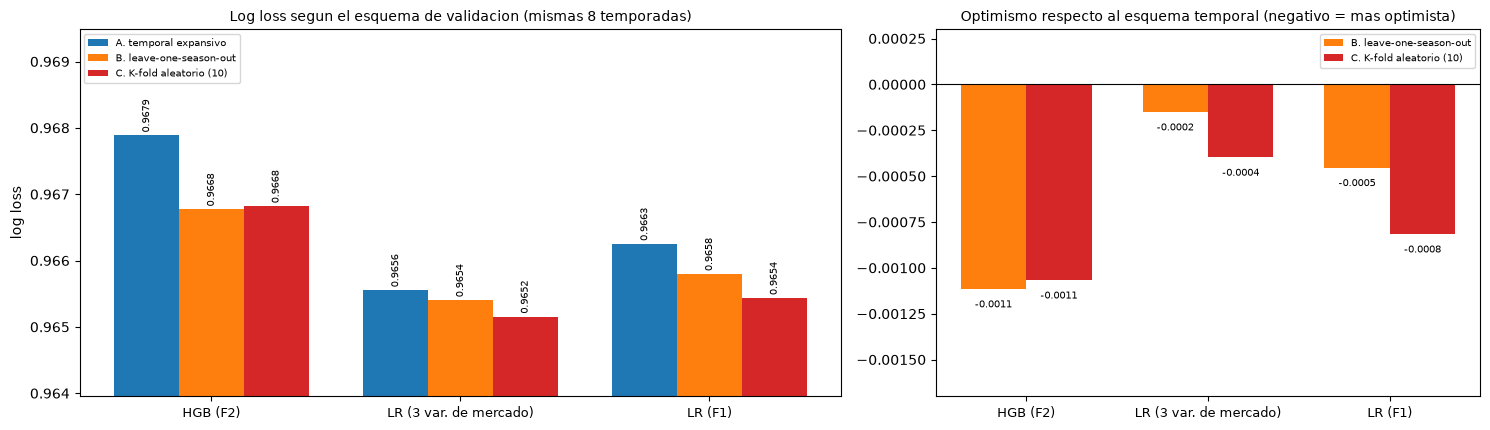

In [2]:
MKT = [f for f in ['MKT_logit', 'MKT_pD', 'MKT_margin'] if f in fs['F2_completo']]
F1, F2 = fs['F1_sin_nan'], fs['F2_completo']
yy = df['FTR'].map({'H': 0, 'D': 1, 'A': 2}).to_numpy()
seas = df['Season'].to_numpy()
EVAL = seas >= 1819

lr_m = lambda: make_pipeline(StandardScaler(), LogisticRegression(C=HP['LR_clas']['C'], max_iter=5000))
hgb_m = lambda: HistGradientBoostingClassifier(learning_rate=HP['HGB_clas']['learning_rate'], max_depth=int(HP['HGB_clas']['max_depth']),
        min_samples_leaf=int(HP['HGB_clas']['min_samples_leaf']), max_iter=int(HP['HGB_clas']['max_iter']), l2_regularization=1.0, random_state=42)
MODELOS = {'LR (3 var. de mercado)': (lr_m, MKT), 'LR (F1)': (lr_m, F1), 'HGB (F2)': (hgb_m, F2)}

def esquema(nombre):
    pred = np.full((len(df), 3), np.nan)
    if nombre == 'A':
        splits = [(seas < s, seas == s) for s in sorted(set(seas[EVAL]))]
    elif nombre == 'B':
        splits = [(seas != s, seas == s) for s in sorted(set(seas[EVAL]))]
    else:
        skf = StratifiedKFold(10, shuffle=True, random_state=0)
        splits = [(np.isin(np.arange(len(df)), a), np.isin(np.arange(len(df)), b)) for a, b in skf.split(df, yy)]
    return splits

filas = []
for nom_m, (fab, cols) in MODELOS.items():
    for esq in 'ABC':
        pred = np.full((len(df), 3), np.nan)
        for tr, va in esquema(esq):
            pred[va] = fab().fit(df.loc[tr, cols], yy[tr]).predict_proba(df.loc[va, cols])
        # log loss por temporada de evaluacion (misma definicion de fold en los tres esquemas)
        ll_f = [log_loss(yy[seas == s], pred[seas == s], labels=[0, 1, 2]) for s in sorted(set(seas[EVAL]))]
        filas.append(dict(modelo=nom_m, esquema={'A': 'A. temporal expansivo', 'B': 'B. leave-one-season-out', 'C': 'C. K-fold aleatorio (10)'}[esq],
                          ll_media=np.mean(ll_f), ll_std=np.std(ll_f, ddof=1)))
cv = pd.DataFrame(filas)
tab = cv.pivot(index='modelo', columns='esquema', values='ll_media')
esq_n = ['A. temporal expansivo', 'B. leave-one-season-out', 'C. K-fold aleatorio (10)']; colores = ['tab:blue', 'tab:orange', 'tab:red']
fig, axs = plt.subplots(1, 2, figsize=(15, 4.4), gridspec_kw={'width_ratios': [1.4, 1]})
xs = np.arange(len(tab)); w = 0.26
for k, (e_, c_) in enumerate(zip(esq_n, colores)):
    axs[0].bar(xs + (k - 1) * w, tab[e_], w, color=c_, label=e_)
    for x_, v in zip(xs + (k - 1) * w, tab[e_]): axs[0].text(x_, v + 0.00008, f'{v:.4f}', ha='center', fontsize=7, rotation=90)
axs[0].set_xticks(xs); axs[0].set_xticklabels(tab.index, fontsize=9); axs[0].set_ylim(tab.to_numpy().min() - 0.0012, tab.to_numpy().max() + 0.0016); axs[0].legend(fontsize=7, loc='upper left'); axs[0].set_title('Log loss segun el esquema de validacion (mismas 8 temporadas)', fontsize=10); axs[0].set_ylabel('log loss')
dif = tab.sub(tab[esq_n[0]], axis=0)[esq_n[1:]]
for k, (e_, c_) in enumerate(zip(esq_n[1:], colores[1:])):
    axs[1].bar(xs + (k - 0.5) * 0.36, dif[e_], 0.36, color=c_, label=e_); 
    for x_, v in zip(xs + (k - 0.5) * 0.36, dif[e_]): axs[1].text(x_, v - 0.00006, f'{v:+.4f}', ha='center', va='top', fontsize=7)
axs[1].axhline(0, color='k', lw=0.8); axs[1].set_xticks(xs); axs[1].set_xticklabels(tab.index, fontsize=9); axs[1].set_ylim(-0.0017, 0.0003); axs[1].set_title('Optimismo respecto al esquema temporal (negativo = mas optimista)', fontsize=10); axs[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

**Qué encontramos.** Los tres esquemas dan prácticamente el mismo log loss, y el temporal es el **más pesimista** (el único que no mira el futuro):

| Modelo | A. temporal | B. leave-one-season-out | C. K-fold aleatorio (10) |
|---|---|---|---|
| LR (3 var. de mercado) | 0.9656 | 0.9654 (−0.0002) | 0.9652 (−0.0004) |
| LR (F1) | 0.9663 | 0.9658 (−0.0005) | 0.9654 (−0.0008) |
| HGB (F2) | 0.9679 | 0.9668 (−0.0011) | 0.9668 (−0.0011) |

- El optimismo de los esquemas que ven el futuro es de **0.0002 a 0.0011**: diez veces menor que la variación entre temporadas (± 0.013). Es mayor para HGB (el modelo que más puede aprovechar partidos vecinos y la forma reciente) que para la LR sobre cuotas, cuya única información es el precio del partido.
- El desvío entre folds es idéntico en los tres esquemas (≈ 0.013): la variabilidad dominante es la **temporada** (azar del fútbol), no el esquema.

**Qué significa para nuestro caso.** Podemos afirmar en el informe que la elección de la validación temporal no es lo que explica nuestros resultados: un esquema más "fácil" daría casi lo mismo. Y dejamos de preocuparnos por haber sido demasiado duros o demasiado blandos al evaluar.

**Decisión.** Mantener la validación temporal expansiva. No cambia las conclusiones —en ningún esquema HGB supera a la LR—, pero es la única sin ventaja injusta y la que imita el uso real (predecir lo que viene). Esto sirve para el informe: *se comparó contra K-fold y leave-one-season-out y las diferencias son ≤ 0.0011*.

## Paso 2 — Métricas completas y curvas ROC

**Qué vamos a hacer.** Para los ocho modelos, calcular sobre los 24,183 partidos de evaluación (y por fold):

- **Log loss, Brier multiclase, RPS, accuracy y balanced accuracy.**
- **AUC (uno contra el resto)** para H, D y A, y su promedio (**AUC macro**).
- **Curvas ROC** de los tres resultados.

**Por qué.** El AUC mide **ordenamiento** (¿los partidos que terminan en local tienen mayor `P(H)` que los que no?), independientemente de la calibración. Es la métrica de discriminación que complementa a la log loss (que mezcla discriminación y calibración). El empate suele ser el resultado más difícil: su AUC permite ver cuánto.

**Cómo se lee.** AUC = 0.5 es azar; el prior (probabilidades constantes) da exactamente 0.5 y sirve de control.

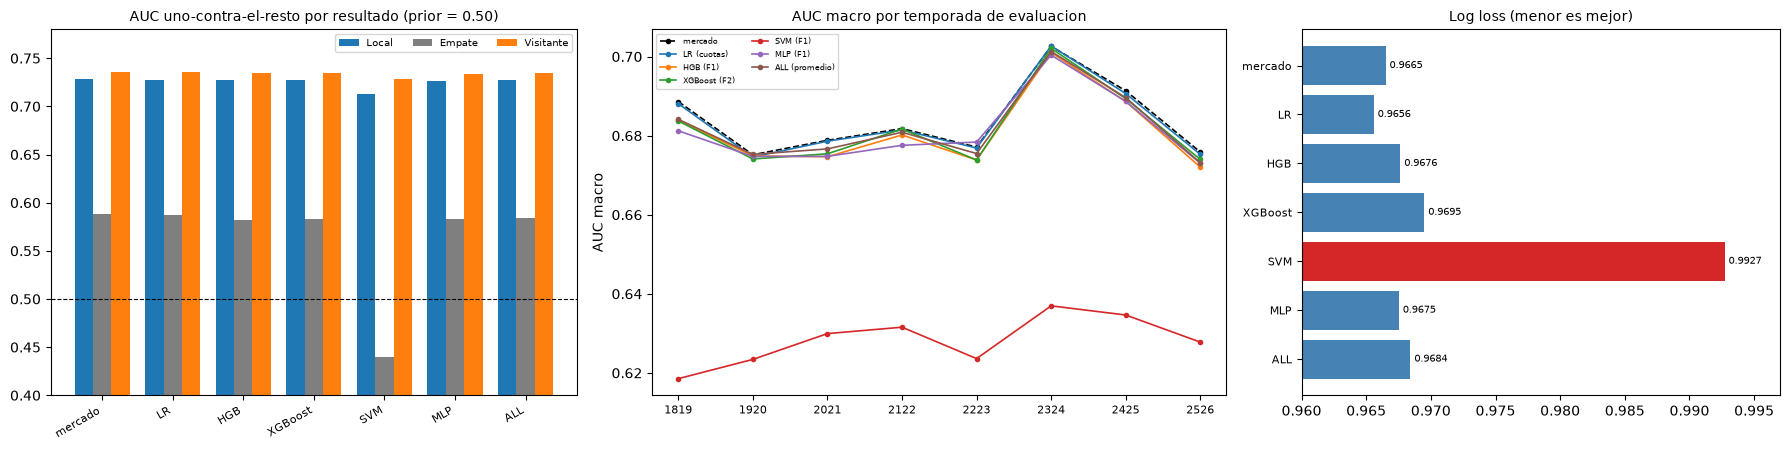

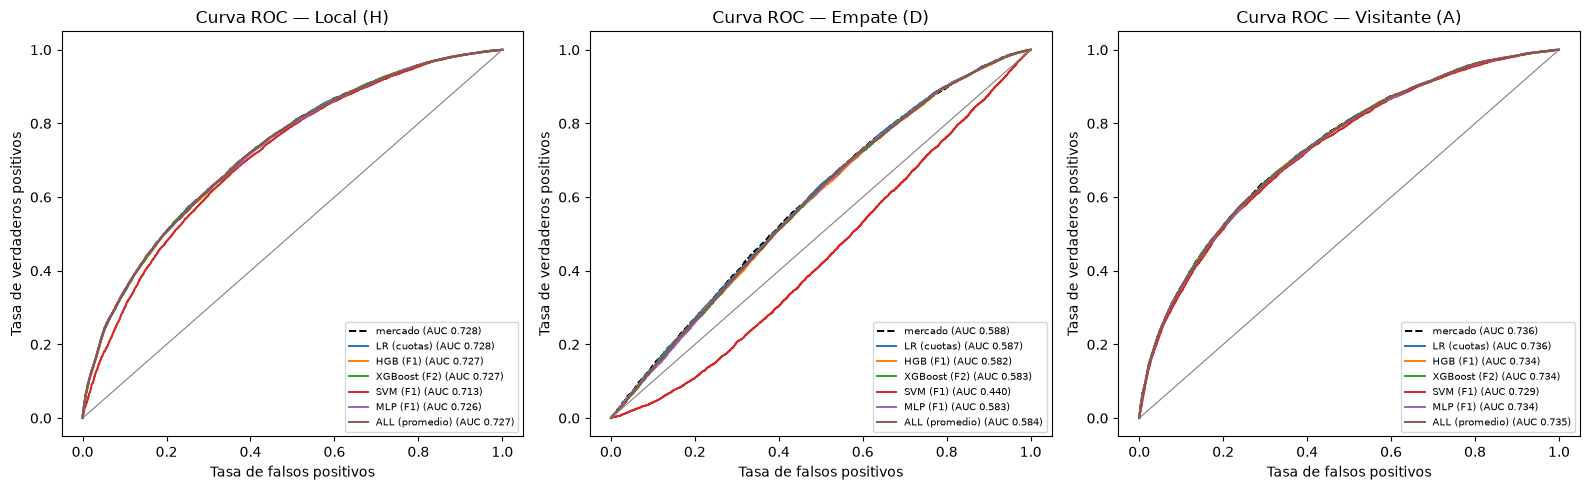

In [3]:
def brier(Pm, yv): return float(np.mean(np.sum((Pm - np.eye(3)[yv]) ** 2, axis=1)))
def rps(Pm, yv):
    O = np.eye(3)[yv]; return float(np.mean(0.5 * (((np.cumsum(Pm, 1) - np.cumsum(O, 1))[:, :2]) ** 2).sum(1)))
def aucs(Pm, yv):
    a = []
    for j in range(3):
        o = (yv == j)
        a.append(roc_auc_score(o, Pm[:, j]) if 0 < o.sum() < len(o) else np.nan)
    return a

filas = []
for n in NOMBRES:
    a = aucs(P[n], y)
    filas.append(dict(modelo=n, log_loss=log_loss(y, P[n], labels=[0, 1, 2]), brier=brier(P[n], y), rps=rps(P[n], y),
                      acc=accuracy_score(y, P[n].argmax(1)), bal_acc=balanced_accuracy_score(y, P[n].argmax(1)),
                      AUC_H=a[0], AUC_D=a[1], AUC_A=a[2], AUC_macro=float(np.mean(a))))
met = pd.DataFrame(filas).set_index('modelo')

auc_f = pd.DataFrame({n: [np.mean(aucs(P[n][fold == s], y[fold == s])) for s in FOLDS] for n in NOMBRES[1:]}, index=[int(s) for s in FOLDS])

fig, axs = plt.subplots(1, 3, figsize=(18, 4.6), gridspec_kw={'width_ratios': [1.1, 1.2, 1]})
orden = list(met.index[1:])
xs = np.arange(len(orden)); w = 0.26
for k, (col, lab, c_) in enumerate((('AUC_H', 'Local', 'tab:blue'), ('AUC_D', 'Empate', 'tab:gray'), ('AUC_A', 'Visitante', 'tab:orange'))):
    axs[0].bar(xs + (k - 1) * w, met.loc[orden, col], w, label=lab, color=c_)
axs[0].axhline(0.5, color='k', ls='--', lw=0.8); axs[0].set_xticks(xs); axs[0].set_xticklabels([o.split(' (')[0] for o in orden], rotation=30, ha='right', fontsize=8); axs[0].set_ylim(0.4, 0.78); axs[0].legend(fontsize=7, ncol=3); axs[0].set_title('AUC uno-contra-el-resto por resultado (prior = 0.50)', fontsize=10)
for n, c_ in zip(NOMBRES[1:], ['k', 'tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'tab:purple', 'tab:brown']):
    axs[1].plot(range(len(FOLDS)), auc_f[n], marker='o', ms=3, lw=1.2, color=c_, ls='--' if n == 'mercado' else '-', label=n)
axs[1].set_xticks(range(len(FOLDS))); axs[1].set_xticklabels([int(s_) for s_ in FOLDS], fontsize=8); axs[1].legend(fontsize=6, ncol=2); axs[1].set_title('AUC macro por temporada de evaluacion', fontsize=10); axs[1].set_ylabel('AUC macro')
axs[2].barh(range(len(orden))[::-1], met.loc[orden, 'log_loss'], color=['tab:red' if v > 0.99 else 'steelblue' for v in met.loc[orden, 'log_loss']]); axs[2].set_yticks(range(len(orden))[::-1]); axs[2].set_yticklabels([o.split(' (')[0] for o in orden], fontsize=8); axs[2].set_xlim(0.96, 0.997)
for yi, v in zip(range(len(orden))[::-1], met.loc[orden, 'log_loss']): axs[2].text(v + 0.0003, yi, f'{v:.4f}', va='center', fontsize=7)
axs[2].set_title('Log loss (menor es mejor)', fontsize=10)
plt.tight_layout(); plt.show()

fig, axs = plt.subplots(1, 3, figsize=(16, 5))
estilos = {'mercado': ('k', '--'), 'LR (cuotas)': ('tab:blue', '-'), 'HGB (F1)': ('tab:orange', '-'), 'XGBoost (F2)': ('tab:green', '-'),
           'SVM (F1)': ('tab:red', '-'), 'MLP (F1)': ('tab:purple', '-'), 'ALL (promedio)': ('tab:brown', '-')}
for j, (ax, l) in enumerate(zip(axs, ['Local (H)', 'Empate (D)', 'Visitante (A)'])):
    for n, (c, ls) in estilos.items():
        fpr, tpr, _ = roc_curve(y == j, P[n][:, j])
        ax.plot(fpr, tpr, color=c, ls=ls, lw=1.4, label=f'{n} (AUC {roc_auc_score(y == j, P[n][:, j]):.3f})')
    ax.plot([0, 1], [0, 1], color='gray', lw=0.8)
    ax.set_title(f'Curva ROC — {l}'); ax.set_xlabel('Tasa de falsos positivos'); ax.set_ylabel('Tasa de verdaderos positivos'); ax.legend(fontsize=7, loc='lower right')
plt.tight_layout(); plt.show()

**Qué encontramos.** Métricas sobre los 24,183 partidos de evaluación:

| Modelo | Log loss | Brier | RPS | Acc. | Bal. acc. | AUC H | AUC D | AUC A | **AUC macro** |
|---|---|---|---|---|---|---|---|---|---|
| Prior | 1.0727 | 0.649 | 0.2307 | 0.437 | 0.333 | 0.500 | 0.496 | 0.498 | 0.498 |
| Mercado | 0.9665 | 0.5739 | 0.1948 | 0.538 | 0.465 | 0.728 | 0.588 | 0.736 | 0.684 |
| **LR (cuotas)** | **0.9656** | **0.5733** | **0.1946** | 0.538 | 0.465 | 0.728 | 0.587 | 0.736 | 0.6835 |
| HGB (F1) | 0.9676 | 0.5746 | 0.1950 | 0.538 | 0.466 | 0.727 | 0.582 | 0.734 | 0.681 |
| XGBoost (F2) | 0.9695 | 0.5755 | 0.1955 | 0.537 | 0.464 | 0.727 | 0.583 | 0.734 | 0.682 |
| MLP (F1) | 0.9675 | 0.5746 | 0.1951 | 0.535 | 0.461 | 0.727 | 0.583 | 0.734 | 0.681 |
| ALL | 0.9684 | 0.5751 | 0.1952 | 0.537 | 0.463 | 0.727 | 0.584 | 0.735 | 0.682 |
| SVM (F1) | 0.9927 | 0.5920 | 0.2008 | 0.532 | 0.454 | 0.713 | **0.440** | 0.729 | 0.627 |

1. **El prior da AUC = 0.50** en los tres resultados, como corresponde a un clasificador sin información (control correcto).
2. **El ordenamiento de los modelos por AUC es el mismo que por log loss, Brier y RPS:** mercado ≈ LR > HGB ≈ MLP ≈ XGBoost ≈ ALL ≫ SVM. Cuatro métricas independientes de naturaleza distinta (discriminación, calibración, error cuadrático, probabilidad ordinal) coinciden: la conclusión no depende de la métrica.
3. **Se discrimina mucho mejor local y visitante (AUC ≈ 0.73) que el empate (≈ 0.59).** El empate es el resultado que el mercado y todos los modelos anticipan peor, como ya se sabía en la literatura.
4. **El AUC es muy estable entre folds** (desvío 0.010; la LR varía de 0.675 a 0.703): la temporada 2023/24 es "más fácil" para todos los modelos por igual.
5. **El SVM tiene AUC del empate de 0.440, por debajo del azar (0.5).** Esto no es mala suerte: la columna `P(D)` del SVM está **invertida** (pendiente de calibración −1.59, ver Paso 4). Es un defecto conocido de las probabilidades multiclase de `SVC(probability=True)` (acoplamiento de clasificadores uno-contra-uno con escalamiento de Platt): el empate es la clase que queda "en el medio" y su probabilidad sale anticorrelacionada con la verdad. Explica **por qué** el SVM pierde 0.027 de log loss y no solo "que" pierde (la recalibración del Paso 5 lo confirma).

**Qué significa para nuestro caso.** Que cuatro métricas distintas pongan a los modelos en el mismo orden hace que la conclusión (la LR sobre cuotas es la mejor) no dependa de la métrica elegida. Además el AUC aclara qué se puede predecir: local y visitante sí (0.73), el empate casi no (0.59). Y explica por qué el SVM pierde: su probabilidad de empate está invertida.

**Decisión.** Reportar AUC macro y por clase junto a la log loss. La conclusión del proyecto no cambia, y la evidencia ahora es más sólida: mejor modelo = LR sobre cuotas, por log loss, Brier, RPS y AUC.

## Paso 3 — Matrices de confusión y métricas por clase

**Qué vamos a hacer.** Para el mercado y la LR sobre cuotas, mostrar la matriz de confusión del resultado más probable (`argmax`) y la precisión, la exhaustividad (*recall*) y el F1 por clase.

**Por qué.** La accuracy esconde que el empate casi nunca es el resultado más probable: un modelo bien calibrado casi nunca *predice* empate aunque lo asigne un 25–30% de probabilidad. Las matrices lo hacen visible y explican por qué el balanced accuracy es mucho menor que la accuracy.

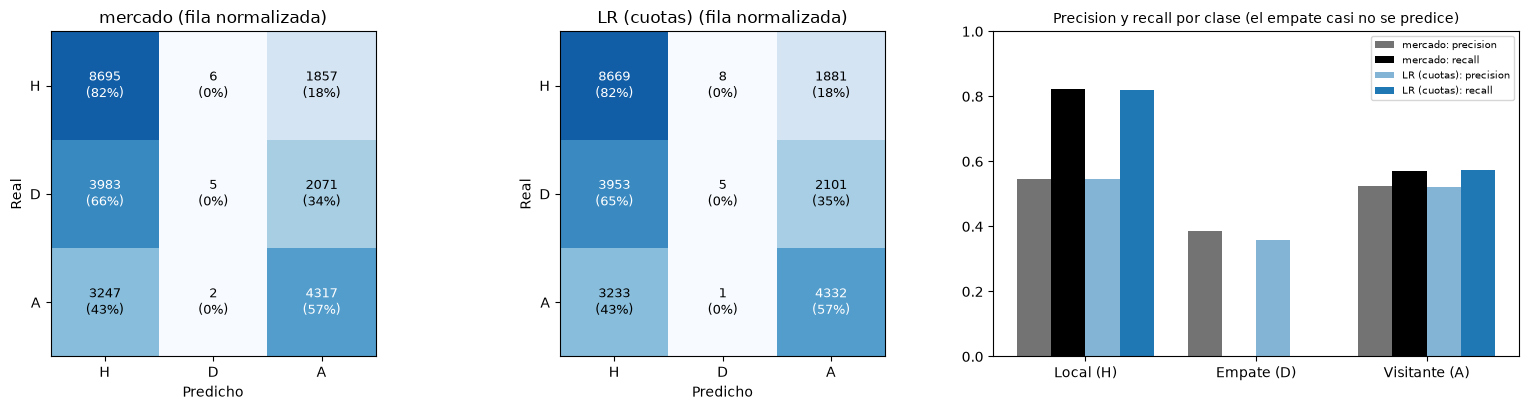

Veces que cada modelo predice empate (argmax): {'mercado': 13, 'LR (cuotas)': 14, 'HGB (F1)': 125, 'XGBoost (F2)': 0, 'SVM (F1)': 0, 'MLP (F1)': 0, 'ALL (promedio)': 0}


In [4]:
fig, axs = plt.subplots(1, 3, figsize=(16, 4.2), gridspec_kw={'width_ratios': [1, 1, 1.1]})
for ax, n in zip(axs[:2], ['mercado', 'LR (cuotas)']):
    cm = confusion_matrix(y, P[n].argmax(1), labels=[0, 1, 2])
    cmn = cm / cm.sum(1, keepdims=True)
    ax.imshow(cmn, cmap='Blues', vmin=0, vmax=1)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f'{cm[i, j]}\n({cmn[i, j]:.0%})', ha='center', va='center', color='white' if cmn[i, j] > 0.5 else 'black', fontsize=9)
    ax.set_xticks(range(3)); ax.set_xticklabels(['H', 'D', 'A']); ax.set_yticks(range(3)); ax.set_yticklabels(['H', 'D', 'A'])
    ax.set_xlabel('Predicho'); ax.set_ylabel('Real'); ax.set_title(f'{n} (fila normalizada)')
xs = np.arange(3); w = 0.2
for k, (n, c_) in enumerate((('mercado', 'k'), ('LR (cuotas)', 'tab:blue'))):
    pr_, rc_, f_, s_ = precision_recall_fscore_support(y, P[n].argmax(1), labels=[0, 1, 2], zero_division=0)
    axs[2].bar(xs + (2 * k - 1.5) * w, pr_, w, color=c_, alpha=0.55, label=f'{n}: precision'); axs[2].bar(xs + (2 * k - 0.5) * w, rc_, w, color=c_, label=f'{n}: recall')
axs[2].set_xticks(xs); axs[2].set_xticklabels(['Local (H)', 'Empate (D)', 'Visitante (A)']); axs[2].legend(fontsize=7); axs[2].set_ylim(0, 1); axs[2].set_title('Precision y recall por clase (el empate casi no se predice)', fontsize=10)
plt.tight_layout(); plt.show()
print('Veces que cada modelo predice empate (argmax):', {n: int((P[n].argmax(1) == 1).sum()) for n in NOMBRES[1:]})

**Qué encontramos.**

- El mercado y la LR **casi nunca predicen empate**: 13 y 14 veces en 24,183 partidos (recall 0.1%), aunque el empate ocurre en el 25%. Es lo esperable de un modelo calibrado: la probabilidad del empate nunca supera la de local o visitante (rara vez pasa de 0.33).
- Local: recall 82%, precisión 55%. Visitante: recall 57%, precisión 52%. La accuracy de 53.8% es en realidad una mezcla de "casi siempre acierta al local" y "acierta a medias al visitante".
- La **balanced accuracy** (46.5%) es la medida honesta para clases desbalanceadas y siempre queda 7 pp por debajo de la accuracy.
- Solo HGB predice empate con alguna frecuencia (125 veces), sin ganar nada por ello.

**Qué significa para nuestro caso.** Para nuestro caso no tiene sentido usar la accuracy como objetivo: ninguna versión del modelo (ni el mercado) va a "acertar" empates. Lo valioso es la probabilidad bien calibrada, no la etiqueta.

**Decisión.** No usar la accuracy como métrica principal (confirma lo ya visto en `04_modelo.ipynb`, hipótesis iii). Reportar la matriz de confusión y la balanced accuracy como complemento descriptivo; las decisiones se toman con log loss y AUC.

## Paso 4 — Calibración: ECE, MCE, pendiente y diagramas de fiabilidad

**Qué vamos a hacer.** Medir la calibración de cada modelo con varias definiciones, porque el ECE depende de cómo se agrupan las probabilidades:

- **ECE de igual ancho** (10 tramos de 0.1; el de `04_modelo.ipynb`).
- **ECE de igual masa** (10 tramos con el mismo número de partidos): no se ve distorsionado por tramos casi vacíos.
- **MCE** (*maximum calibration error*): el peor tramo con al menos 100 partidos.
- **Pendiente e intercepto de calibración** por resultado (regresión logística del resultado sobre `logit(p)`; ideal: 1 y 0).
- **ECE de la etiqueta más probable** (*top-label*): ¿es correcta la confianza del modelo en su predicción?

Además, **diagramas de fiabilidad** de los tres resultados con intervalos de Wilson.

**Por qué.** Un único ECE de 10 tramos puede cambiar el orden de los modelos al cambiar los tramos; si los resultados coinciden con las tres definiciones, la conclusión es robusta. Y los *value bets* dependen de la calibración condicional, no de la media (ver `04_modelo.ipynb`, hipótesis iii).

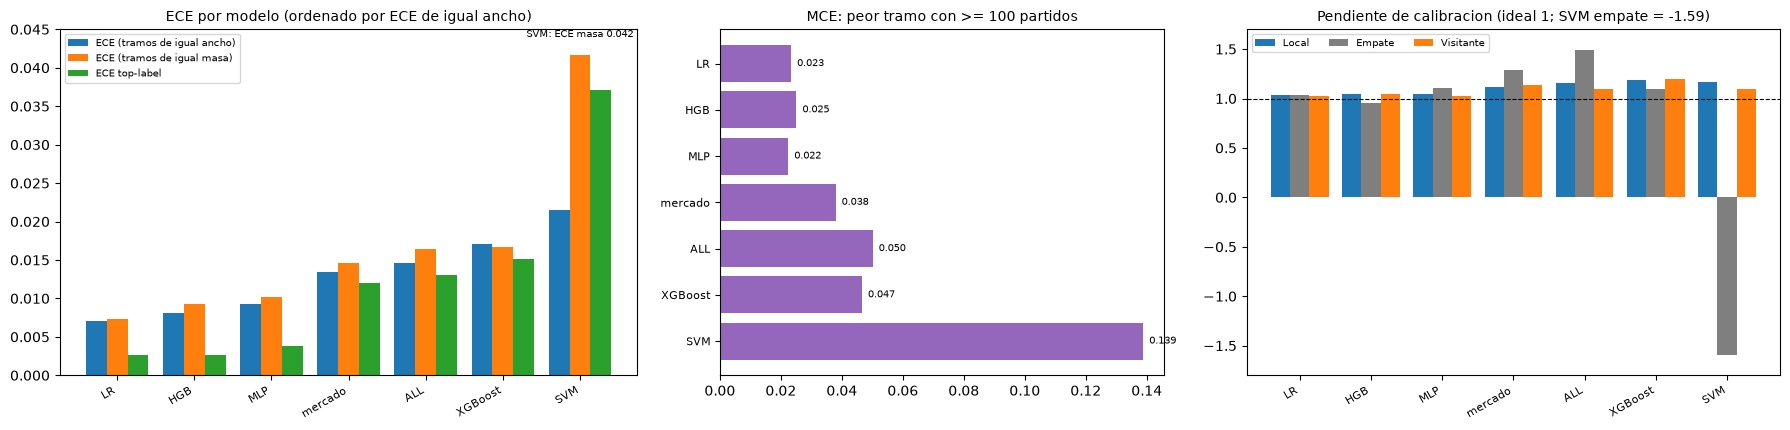

Orden por ECE (ancho): ['LR (cuotas)', 'HGB (F1)', 'MLP (F1)', 'mercado', 'ALL (promedio)', 'XGBoost (F2)', 'SVM (F1)']
Orden por ECE (masa) : ['LR (cuotas)', 'HGB (F1)', 'MLP (F1)', 'mercado', 'ALL (promedio)', 'XGBoost (F2)', 'SVM (F1)']


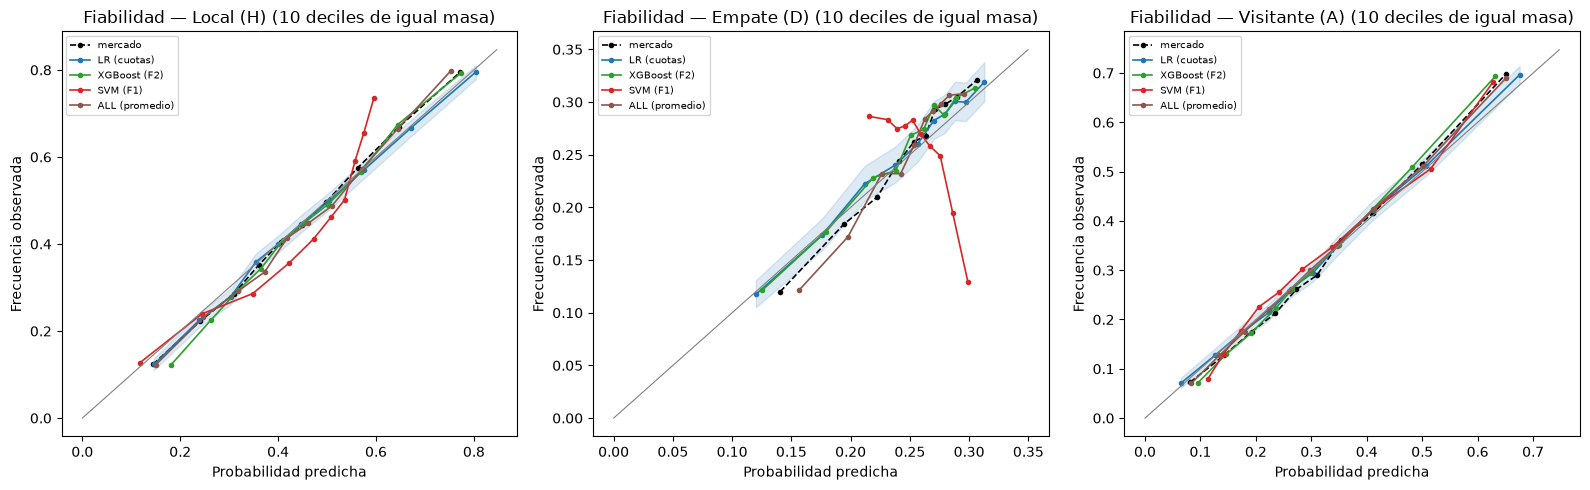

In [5]:
def ece_w(p, o, nb=10):
    b = np.minimum((p * nb).astype(int), nb - 1)
    return float(sum((b == k).mean() * abs(o[b == k].mean() - p[b == k].mean()) for k in np.unique(b)))
def ece_q(p, o, nb=10):
    b = pd.qcut(p, nb, labels=False, duplicates='drop')
    return float(sum((b == k).mean() * abs(o[b == k].mean() - p[b == k].mean()) for k in np.unique(b)))
def mce(p, o, nb=10, nmin=100):
    b = np.minimum((p * nb).astype(int), nb - 1)
    v = [abs(o[b == k].mean() - p[b == k].mean()) for k in np.unique(b) if (b == k).sum() >= nmin]
    return float(max(v)) if v else np.nan
def pend(p, o):
    pc = np.clip(p, 1e-6, 1 - 1e-6)
    m = LogisticRegression(C=1e6, max_iter=1000).fit(np.log(pc / (1 - pc)).reshape(-1, 1), o)
    return float(m.coef_[0, 0]), float(m.intercept_[0])

filas = []
for n in NOMBRES[1:]:
    ew = [ece_w(P[n][:, j], y == j) for j in range(3)]
    eq = [ece_q(P[n][:, j], y == j) for j in range(3)]
    mc = [mce(P[n][:, j], y == j) for j in range(3)]
    ps = [pend(P[n][:, j], y == j) for j in range(3)]
    conf = P[n].max(1); ok = (P[n].argmax(1) == y).astype(float)
    filas.append(dict(modelo=n, ECE_ancho=np.mean(ew), ECE_masa=np.mean(eq), MCE=np.nanmean(mc), ECE_top=ece_w(conf, ok),
                      pend_H=ps[0][0], pend_D=ps[1][0], pend_A=ps[2][0], inter_H=ps[0][1], inter_D=ps[1][1], inter_A=ps[2][1]))
cal = pd.DataFrame(filas).set_index('modelo')
fig, axs = plt.subplots(1, 3, figsize=(18, 4.4), gridspec_kw={'width_ratios': [1.3, 1, 1.2]})
orden = list(cal.sort_values('ECE_ancho').index); xs = np.arange(len(orden)); w = 0.27
for k, (col, lab, c_) in enumerate((('ECE_ancho', 'ECE (tramos de igual ancho)', 'tab:blue'), ('ECE_masa', 'ECE (tramos de igual masa)', 'tab:orange'), ('ECE_top', 'ECE top-label', 'tab:green'))):
    axs[0].bar(xs + (k - 1) * w, cal.loc[orden, col], w, label=lab, color=c_)
axs[0].set_xticks(xs); axs[0].set_xticklabels([o.split(' (')[0] for o in orden], rotation=30, ha='right', fontsize=8); axs[0].set_ylim(0, 0.045); axs[0].legend(fontsize=7); axs[0].set_title('ECE por modelo (ordenado por ECE de igual ancho)', fontsize=10)
axs[0].annotate('SVM: ECE masa 0.042', (xs[-1], 0.044), fontsize=7, ha='center')
axs[1].barh(range(len(orden))[::-1], cal.loc[orden, 'MCE'], color='tab:purple'); axs[1].set_yticks(range(len(orden))[::-1]); axs[1].set_yticklabels([o.split(' (')[0] for o in orden], fontsize=8)
for yi, v in zip(range(len(orden))[::-1], cal.loc[orden, 'MCE']): axs[1].text(v + 0.002, yi, f'{v:.3f}', va='center', fontsize=7)
axs[1].set_title('MCE: peor tramo con >= 100 partidos', fontsize=10)
for k, (col, lab, c_) in enumerate((('pend_H', 'Local', 'tab:blue'), ('pend_D', 'Empate', 'tab:gray'), ('pend_A', 'Visitante', 'tab:orange'))):
    axs[2].bar(xs + (k - 1) * w, cal.loc[orden, col], w, label=lab, color=c_)
axs[2].axhline(1, color='k', ls='--', lw=0.8); axs[2].set_ylim(-1.8, 1.7); axs[2].set_xticks(xs); axs[2].set_xticklabels([o.split(' (')[0] for o in orden], rotation=30, ha='right', fontsize=8); axs[2].legend(fontsize=7, ncol=3); axs[2].set_title('Pendiente de calibracion (ideal 1; SVM empate = -1.59)', fontsize=10)
plt.tight_layout(); plt.show()
print('Orden por ECE (ancho):', list(cal.ECE_ancho.sort_values().index)); print('Orden por ECE (masa) :', list(cal.ECE_masa.sort_values().index))

def wilson(k, n, z=1.96):
    p = k / n; d = 1 + z ** 2 / n; c = (p + z ** 2 / (2 * n)) / d; h = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / d
    return c - h, c + h
fig, axs = plt.subplots(1, 3, figsize=(16, 5))
for j, (ax, l) in enumerate(zip(axs, ['Local (H)', 'Empate (D)', 'Visitante (A)'])):
    for n, (c, ls) in {'mercado': ('k', '--'), 'LR (cuotas)': ('tab:blue', '-'), 'XGBoost (F2)': ('tab:green', '-'), 'SVM (F1)': ('tab:red', '-'), 'ALL (promedio)': ('tab:brown', '-')}.items():
        p = P[n][:, j]; o = (y == j)
        b = pd.qcut(p, 10, labels=False, duplicates='drop')
        xs = np.array([p[b == k].mean() for k in np.unique(b)]); ys = np.array([o[b == k].mean() for k in np.unique(b)])
        ax.plot(xs, ys, color=c, ls=ls, marker='o', ms=3, lw=1.2, label=n)
        if n == 'LR (cuotas)':
            ci = np.array([wilson(o[b == k].sum(), (b == k).sum()) for k in np.unique(b)])
            ax.fill_between(xs, ci[:, 0], ci[:, 1], color=c, alpha=0.15)
    lim = [0, max(ax.get_xlim()[1], ax.get_ylim()[1])]
    ax.plot(lim, lim, color='gray', lw=0.8); ax.set_title(f'Fiabilidad — {l} (10 deciles de igual masa)'); ax.set_xlabel('Probabilidad predicha'); ax.set_ylabel('Frecuencia observada'); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

**Qué encontramos.**

| Modelo | ECE (ancho) | ECE (masa) | MCE | ECE top-label | Pendiente H / D / A |
|---|---|---|---|---|---|
| **LR (cuotas)** | **0.0071** | **0.0073** | 0.023 | 0.0027 | 1.03 / 1.04 / 1.02 |
| HGB (F1) | 0.0081 | 0.0093 | 0.025 | 0.0027 | 1.05 / 0.95 / 1.05 |
| MLP (F1) | 0.0093 | 0.0101 | 0.022 | 0.0038 | 1.04 / 1.10 / 1.03 |
| Mercado crudo | 0.0134 | 0.0146 | 0.038 | 0.0121 | 1.12 / 1.28 / 1.13 |
| ALL (promedio) | 0.0147 | 0.0164 | 0.050 | 0.0131 | 1.16 / 1.49 / 1.10 |
| XGBoost (F2) | 0.0171 | 0.0167 | 0.047 | 0.0151 | 1.19 / 1.10 / 1.19 |
| SVM (F1) | 0.0215 | 0.0417 | 0.139 | 0.0371 | 1.16 / **−1.59** / 1.10 |

1. **El orden de los modelos es idéntico con ECE de igual ancho y de igual masa** (LR < HGB < MLP < mercado < ALL < XGBoost < SVM): la conclusión es robusta a la definición del ECE.
2. **El mercado crudo está subconfiado** (pendientes 1.12–1.28 > 1): los favoritos ganan más de lo que dice el precio; la LR corrige esto y casi llega a pendiente 1 (1.02–1.04). Es el sesgo favorito–longshot de `06_mercado.ipynb`.
3. **El SVM tiene el peor MCE (0.139)** y una pendiente negativa en el empate: es el diagnóstico del Paso 2.
4. En la métrica *top-label* (¿la confianza en la predicción más probable es correcta?) la LR y el HGB casi no se equivocan (ECE 0.003), mientras que el mercado es peor (0.012).

**Qué significa para nuestro caso.** La calibración es lo que se necesita para comparar con las cuotas y buscar valor. La LR casi corrige la subconfianza del mercado (pendiente de 1.12 a 1.03), y esa conclusión no cambia con la forma de medir el ECE. Los modelos complejos (XGBoost, SVM, ensemble) quedan peor calibrados que el propio mercado.

**Decisión.** La LR sobre cuotas es también el modelo mejor calibrado. Los diagramas de fiabilidad lo confirman visualmente (curva de la LR pegada a la diagonal, banda de Wilson al 95% en azul).

## Paso 5 — Recalibración posterior (temperature / vector scaling)

**Qué vamos a hacer.** Comprobar si los modelos mal calibrados (SVM, XGBoost, ensemble) mejoran con una **recalibración** ajustada en datos pasados. Para cada fold `s` desde 2019/20, se ajusta una regresión logística multinomial sobre `log(P)` con las predicciones fuera de muestra del fold **anterior** (`s − 1`) y se aplica al fold `s`. Es *vector scaling* (3 pesos por resultado), una generalización de *temperature scaling*.

**Por qué.** Separa dos problemas: si un modelo pierde en log loss por **calibración** (arreglable) o por **discriminación** (no arreglable). Es la recalibración que usamos para el mercado y las regresiones de goles en `06_mercado.ipynb` (siempre con la temporada anterior, nunca con la misma).

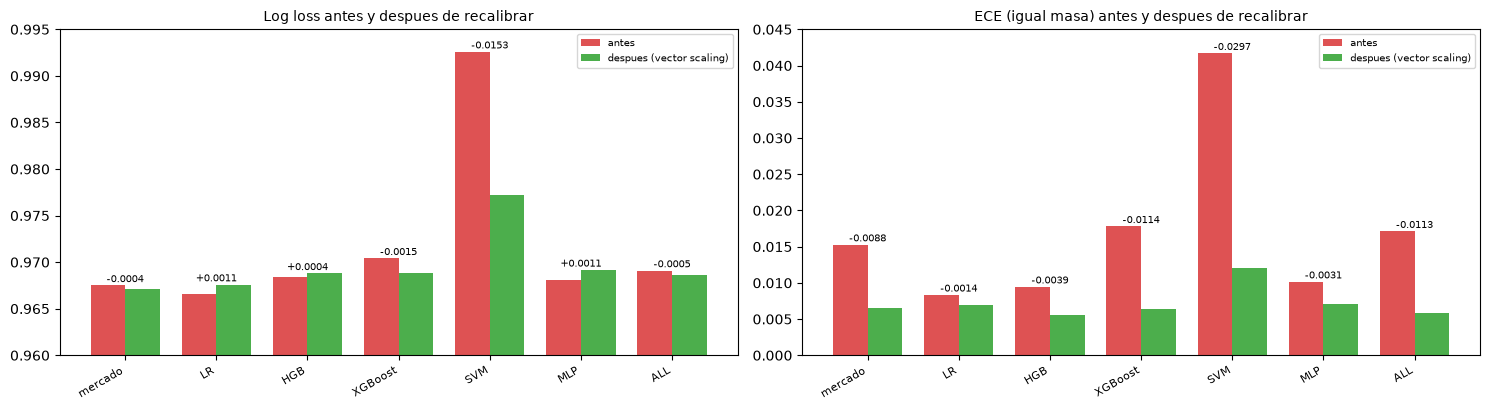

Folds evaluados: [1920, 2021, 2122, 2223, 2324, 2425, 2526] (calibrador ajustado con el fold anterior)


In [6]:
def vec_scale(Pc, yc, Pv):
    Zc, Zv = np.log(np.clip(Pc, 1e-6, 1)), np.log(np.clip(Pv, 1e-6, 1))
    return LogisticRegression(C=10.0, max_iter=3000).fit(Zc, yc).predict_proba(Zv)

folds_r = [s for s in FOLDS if s > FOLDS[0]]
filas = []
for n in NOMBRES[1:]:
    pre, post, yv_all = [], [], []
    for s in folds_r:
        prev = FOLDS[FOLDS.index(s) - 1]
        va, ca = fold == s, fold == prev
        post.append(vec_scale(P[n][ca], y[ca], P[n][va])); pre.append(P[n][va]); yv_all.append(y[va])
    pre, post, yv_all = np.vstack(pre), np.vstack(post), np.concatenate(yv_all)
    e = lambda Q: np.mean([ece_q(Q[:, j], yv_all == j) for j in range(3)])
    filas.append(dict(modelo=n, ll_antes=log_loss(yv_all, pre, labels=[0, 1, 2]), ll_despues=log_loss(yv_all, post, labels=[0, 1, 2]),
                      ECE_antes=e(pre), ECE_despues=e(post), AUC_antes=np.mean(aucs(pre, yv_all)), AUC_despues=np.mean(aucs(post, yv_all))))
rc = pd.DataFrame(filas).set_index('modelo'); rc['mejora_ll'] = rc.ll_antes - rc.ll_despues
fig, axs = plt.subplots(1, 2, figsize=(15, 4.2))
xs = np.arange(len(rc)); w = 0.38
for ax, (a_, d_, tit, yl) in zip(axs, (('ll_antes', 'll_despues', 'Log loss antes y despues de recalibrar', (0.96, 0.995)), ('ECE_antes', 'ECE_despues', 'ECE (igual masa) antes y despues de recalibrar', (0, 0.045)))):
    ax.bar(xs - w / 2, rc[a_], w, color='tab:red', alpha=0.8, label='antes'); ax.bar(xs + w / 2, rc[d_], w, color='tab:green', alpha=0.85, label='despues (vector scaling)')
    ax.set_xticks(xs); ax.set_xticklabels([o.split(' (')[0] for o in rc.index], rotation=30, ha='right', fontsize=8); ax.set_ylim(*yl); ax.legend(fontsize=7); ax.set_title(tit, fontsize=10)
    for x_, v1, v2 in zip(xs, rc[a_], rc[d_]): ax.text(x_, max(v1, v2) + (yl[1] - yl[0]) * 0.01, f'{v2 - v1:+.4f}', ha='center', fontsize=7)
plt.tight_layout(); plt.show()
print(f'Folds evaluados: {[int(s) for s in folds_r]} (calibrador ajustado con el fold anterior)')

**Qué encontramos.** Ajustando un *vector scaling* con el fold anterior y aplicándolo al siguiente:

| Modelo | Log loss antes → después | ECE antes → después |
|---|---|---|
| SVM (F1) | 0.9926 → **0.9773** (−0.0153) | 0.0417 → 0.0120 |
| XGBoost (F2) | 0.9704 → 0.9689 (−0.0015) | 0.0178 → 0.0064 |
| ALL (promedio) | 0.9691 → 0.9686 (−0.0005) | 0.0171 → 0.0058 |
| Mercado | 0.9675 → 0.9671 (−0.0004) | 0.0153 → 0.0065 |
| HGB (F1) | 0.9684 → 0.9688 (+0.0004) | 0.0095 → 0.0056 |
| LR (cuotas) | 0.9665 → 0.9676 (+0.0011) | 0.0083 → 0.0070 |
| MLP (F1) | 0.9681 → 0.9692 (+0.0011) | 0.0102 → 0.0071 |

1. **La recalibración baja el ECE de todos los modelos** (a 0.006–0.012), pero **solo mejora el log loss de los que estaban mal calibrados** (SVM, XGBoost, ALL, mercado). A los ya bien calibrados (LR, HGB, MLP) les *empeora* un poco: con una sola temporada de calibración (~3,000 partidos) el calibrador añade ruido.
2. **El SVM recupera casi todo lo posible** (−0.0153) pero sigue siendo el peor (0.9773 > 0.9676 de la LR): la recalibración arregla la parte de calibración (incluida la inversión del empate) pero no la discriminación.
3. **Ni siquiera recalibrados** XGBoost, ALL o SVM superan a la LR sobre cuotas (0.9665 en estos 7 folds).

**Qué significa para nuestro caso.** Los modelos complejos pierden por **dos** razones: calibración (arreglable, como muestra el SVM al ganar 0.015) y capacidad de ordenar (que no se arregla). Aun arreglada la primera, ninguno alcanza a la LR, así que seguir complicando el modelo no es el camino.

**Decisión.** No recalibrar la LR sobre cuotas (ya lo está). La recalibración queda como evidencia de que el peor desempeño de los modelos complejos **no** se debe solo a calibración deficiente.

## Paso 6 — Bootstrap por bloques y corrección por comparaciones múltiples

**Qué vamos a hacer.** Repetir la comparación del Paso 7 de `04_modelo.ipynb` (cada modelo frente a la LR sobre cuotas y frente al mercado crudo) con tres cambios:

1. **Bootstrap por bloques** `(temporada, semana)`: se remuestrean bloques completos, no partidos (2,000 réplicas para log loss y Brier; 300 para AUC macro, que obliga a recalcular curvas).
2. **Comparar el ancho del intervalo con el del bootstrap de partidos sueltos**, para cuantificar cuánto subestimaba la incertidumbre.
3. **Corrección de Benjamini–Hochberg al 5%** sobre las 14 comparaciones de log loss (ISLP cap. 13), porque se hacen 14 pruebas a la vez.

**Valor *p*.** Bootstrap bilateral: `p = 2·min(P(Δ ≤ 0), P(Δ ≥ 0))`, con piso `1/B`.


Razon media de anchos (bloques / partidos sueltos): 1.02 | significativas sin corregir: 11 | tras BH: 11


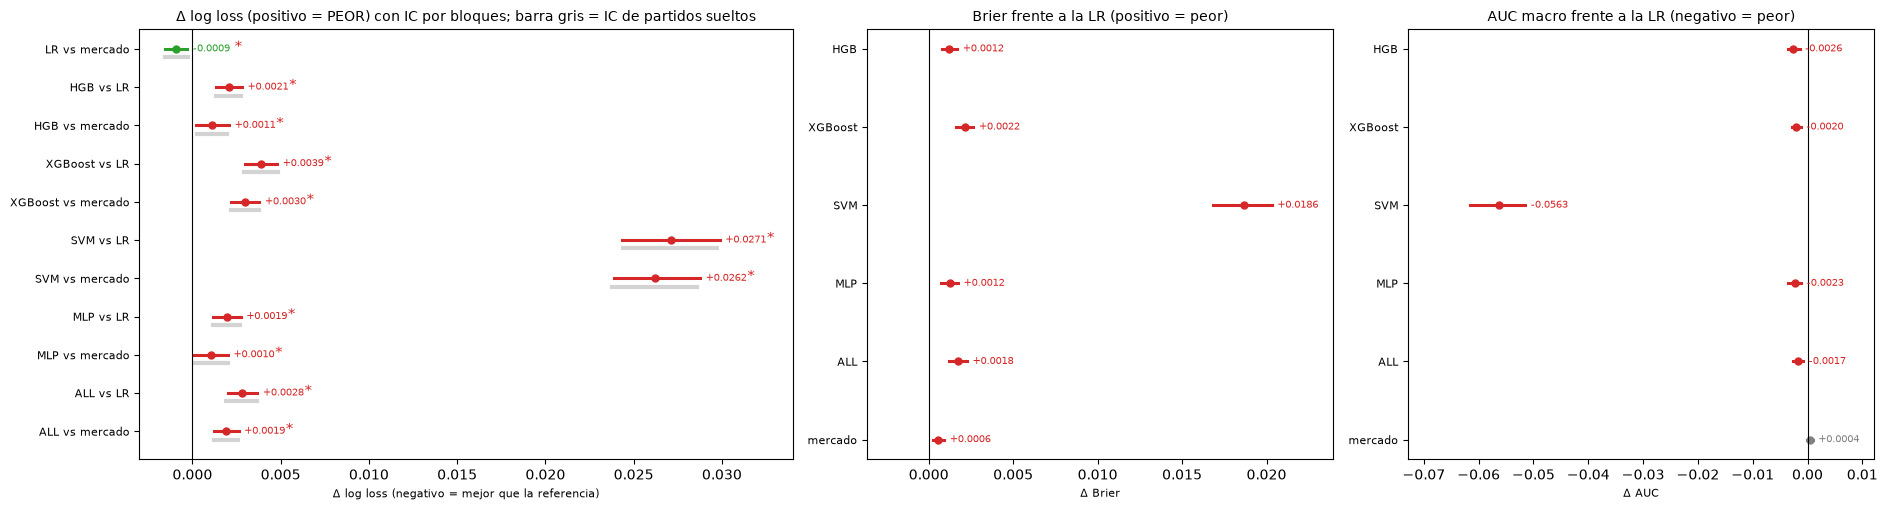

Razon media de anchos (bloques / partidos sueltos): 1.02 | contrastes de log loss significativos sin corregir: 11 de 11 | tras Benjamini-Hochberg: 11 (* en el grafico)


In [7]:
rng = np.random.default_rng(2026)
def pl(n): return -np.log(np.clip(P[n][np.arange(len(y)), y], 1e-9, 1))
def pb(n): return np.sum((P[n] - np.eye(3)[y]) ** 2, axis=1)

# sumas por bloque para remuestrear rapido
cod = pd.factorize(blk)[0]; K = cod.max() + 1; cnt = np.bincount(cod, minlength=K).astype(float)
def boot_bloques(d, B=2000):
    s = np.bincount(cod, weights=d, minlength=K)
    ix = rng.integers(0, K, (B, K))
    return s[ix].sum(1) / cnt[ix].sum(1)
def boot_iid(d, B=2000):
    return np.array([d[rng.integers(0, len(d), len(d))].mean() for _ in range(B)])
def pval(bs): return float(max(2 * min((bs <= 0).mean(), (bs >= 0).mean()), 1 / len(bs)))

def bh(p):
    p = np.asarray(p); o = np.argsort(p); m = len(p); adj = np.empty(m)
    adj[o] = np.minimum.accumulate((p[o] * m / (np.arange(m) + 1))[::-1])[::-1]
    return np.minimum(adj, 1)

filas = []
for n in NOMBRES[2:]:
    for ref in ('LR (cuotas)', 'mercado'):
        if n == ref: continue
        d = pl(n) - pl(ref)
        bb, bi = boot_bloques(d), boot_iid(d, 1000)
        filas.append(dict(modelo=n, vs=ref, delta_ll=d.mean(), lo=np.percentile(bb, 2.5), hi=np.percentile(bb, 97.5), lo_i=np.percentile(bi, 2.5), hi_i=np.percentile(bi, 97.5),
                          ancho_bloques=np.percentile(bb, 97.5) - np.percentile(bb, 2.5), ancho_iid=np.percentile(bi, 97.5) - np.percentile(bi, 2.5), p=pval(bb)))
tb = pd.DataFrame(filas)
tb['p_BH'] = bh(tb.p.values); tb['signif_5pct'] = tb.p_BH < 0.05
tb['razon_anchos'] = tb.ancho_bloques / tb.ancho_iid
print(f'\nRazon media de anchos (bloques / partidos sueltos): {tb.razon_anchos.mean():.2f} | significativas sin corregir: {(tb.p < 0.05).sum()} | tras BH: {tb.signif_5pct.sum()}')

# Brier y AUC macro frente a la LR sobre cuotas
filas2 = []
for n in NOMBRES[3:] + ['mercado']:
    d = pb(n) - pb('LR (cuotas)')
    bb = boot_bloques(d)
    filas2.append(dict(modelo=n, metrica='Brier', delta=d.mean(), lo=np.percentile(bb, 2.5), hi=np.percentile(bb, 97.5), p=pval(bb)))
Bauc = 300
for n in NOMBRES[3:] + ['mercado']:
    dif = []
    for _ in range(Bauc):
        sel = np.concatenate([IDX_BLK[b] for b in rng.integers(0, len(IDX_BLK), len(IDX_BLK))])
        dif.append(np.mean(aucs(P[n][sel], y[sel])) - np.mean(aucs(P['LR (cuotas)'][sel], y[sel])))
    dif = np.array(dif); d0 = np.mean(aucs(P[n], y)) - np.mean(aucs(P['LR (cuotas)'], y))
    filas2.append(dict(modelo=n, metrica='AUC macro', delta=d0, lo=np.percentile(dif, 2.5), hi=np.percentile(dif, 97.5), p=pval(dif)))
t2 = pd.DataFrame(filas2); t2['p_BH'] = bh(t2.p.values)
fig, axs = plt.subplots(1, 3, figsize=(19, 5.2), gridspec_kw={'width_ratios': [1.4, 1, 1]})
et = [f"{r.modelo.split(' (')[0]} vs {'LR' if r.vs.startswith('LR') else 'mercado'}" for r in tb.itertuples()]
forest(axs[0], et, tb.delta_ll.to_numpy(), tb.lo.to_numpy(), tb.hi.to_numpy(), 'Δ log loss (positivo = PEOR) con IC por bloques; barra gris = IC de partidos sueltos')
for yi, r in zip(np.arange(len(tb))[::-1], tb.itertuples()): axs[0].plot([r.lo_i, r.hi_i], [yi - 0.22, yi - 0.22], color='lightgray', lw=3, zorder=0)
for yi, r in zip(np.arange(len(tb))[::-1], tb.itertuples()):
    if r.signif_5pct: axs[0].annotate('*', (r.hi, yi), xytext=(34, -2), textcoords='offset points', fontsize=11, color='tab:red')
axs[0].set_xlim(-0.003, 0.034)
for ax, met, tit, unid in ((axs[1], 'Brier', 'Brier frente a la LR (positivo = peor)', 'Δ Brier'), (axs[2], 'AUC macro', 'AUC macro frente a la LR (negativo = peor)', 'Δ AUC')):
    sub_ = t2[t2.metrica == met]
    forest(ax, [m.split(' (')[0] for m in sub_.modelo], sub_.delta.to_numpy(), sub_.lo.to_numpy(), sub_.hi.to_numpy(), tit, xlabel=unid, positivo_bueno=(met == 'AUC macro'))
plt.tight_layout(); plt.show()
print(f'Razon media de anchos (bloques / partidos sueltos): {tb.razon_anchos.mean():.2f} | contrastes de log loss significativos sin corregir: {(tb.p < 0.05).sum()} de {len(tb)} | tras Benjamini-Hochberg: {tb.signif_5pct.sum()} (* en el grafico)')

**Qué encontramos.**

- **El bootstrap por bloques casi no cambia los intervalos:** la razón entre el ancho del IC por bloques y el de partidos sueltos es **1.02** en promedio (0.95–1.08). Mi sospecha previa de que los IC de `04_modelo.ipynb` eran demasiado estrechos por ignorar la dependencia entre partidos de la misma semana **no se confirma**: la correlación dentro del bloque es despreciable porque la pérdida de un partido depende de su propio azar, no del bloque.
- Los **11 contrastes de log loss son significativos tanto sin corregir como tras Benjamini–Hochberg** (el máximo *p* ajustado es 0.033). Ningún resultado de `04_modelo.ipynb` cambia.
- Todos los modelos son **peores** que la LR sobre cuotas y que el mercado crudo, con el mismo orden de siempre; las diferencias más pequeñas (HGB y MLP frente al mercado, +0.0010/+0.0011) son las menos holgadas (*p*_BH = 0.020 y 0.033).
- **Brier:** todos peores que la LR (HGB y MLP +0.0012; XGBoost +0.0022; SVM +0.0186). **AUC macro:** todos peores (−0.0017 a −0.0026; SVM −0.056). El mercado crudo tiene un AUC igual al de la LR (+0.0004, IC [−0.0002, +0.0009], *p* = 0.19): **la LR mejora la calibración del mercado pero no su capacidad de ordenar partidos**.

**Qué significa para nuestro caso.** Nuestras conclusiones de `04_modelo` **resisten una prueba más exigente**: los intervalos casi no se ensanchan y todos los contrastes siguen significativos tras corregir por pruebas múltiples. Y como el AUC del mercado crudo es igual al de la LR, queda claro que la mejora de la LR es de calibración, no de información.

**Decisión.** Reemplazar en el informe "IC por bootstrap de partidos" por "IC por bootstrap de bloques (temporada-semana) con corrección de Benjamini–Hochberg". Las conclusiones del proyecto se sostienen sin cambios.

## Paso 7 — ¿Qué variables importan, con y sin cuotas?

**Qué vamos a hacer.** Responder con dos medidas distintas cuáles son las variables más relevantes en los dos escenarios (con cuotas y sin cuotas):

1. **Dependencia con el resultado (información mutua, MI):** cuánto sabemos de `FTR` conociendo una sola variable. Se calcula con el entrenamiento previo al último fold. No depende de ningún modelo.
2. **Aporte al modelo (importancia por permutación de grupos):** se entrena un HGB con todas las variables del escenario y, en cada temporada de evaluación, se **baraja un grupo entero** de variables a la vez (precio, plantilla, habilidades, goles y puntos, tiros, Elo, córners/faltas/tarjetas, contexto). Lo que sube el log loss mide cuánto dependía el modelo de ese grupo.

**Por qué.** MI mide dependencia, no aporte: dos variables casi iguales (la calidad del once y sus habilidades, r hasta 0.94) salen ambas altas aunque el modelo use una sola. La permutación mide el aporte, pero con variables correlacionadas reparte mal la importancia si se baraja una por una; por eso se baraja por **grupos**.

In [8]:
from sklearn.feature_selection import mutual_info_classif
sk = pd.read_csv(DATA + 'dataset_skills.csv'); ex = pd.read_csv(DATA + 'dataset_extra.csv')
assert (sk[['Date', 'HomeTeam', 'AwayTeam']].values == df[['Date', 'HomeTeam', 'AwayTeam']].values).all()
assert (ex[['Date', 'HomeTeam', 'AwayTeam']].values == df[['Date', 'HomeTeam', 'AwayTeam']].values).all()
SK = fs['SK_habilidades']
XV = pd.concat([df[[c for c in fs['F2_completo']]].reset_index(drop=True), sk[SK], ex.drop(columns=['Date', 'HomeTeam', 'AwayTeam', 'Season'])], axis=1)
XV = XV.loc[:, ~XV.columns.duplicated()]

def grupo_de(c):
    if c in SK: return 'Habilidades'
    if c.startswith(('MKT_', 'REF_', 'PIN_')): return 'Precio (cuotas)'
    if 'sq_top11' in c or c.startswith(('SQz', 'XIz')): return 'Plantilla'
    if c.startswith('ELO'): return 'Elo'
    if c.startswith(('REST', 'CONG', 'NEW', 'SEASON')): return 'Contexto'
    if 'SOT' in c or c.endswith(('SGF_5', 'SGA_5')): return 'Tiros'
    if c.endswith(('CF_5', 'CA_5', 'FF_5', 'FA_5', 'CardF_5', 'CardA_5')): return 'Córners, faltas, tarjetas'
    return 'Goles y puntos'
GRUPO = {c: grupo_de(c) for c in XV.columns}
print(pd.Series(GRUPO).value_counts().to_string())
ESC = {'Con cuotas': list(XV.columns), 'Sin cuotas': [c for c in XV.columns if GRUPO[c] != 'Precio (cuotas)']}

# 1) MI por variable: entrenamiento previo al ultimo fold, submuestra por velocidad
ult = max(FOLDS)
tr_mi = np.where(seas < ult)[0]; rs = np.random.default_rng(0); tr_mi = np.sort(rs.choice(tr_mi, 15000, replace=False))
MI = {}
for esc, cols in ESC.items():
    Xm = XV.loc[tr_mi, cols]; Xm = Xm.fillna(Xm.median())
    MI[esc] = pd.Series(mutual_info_classif(Xm, yy[tr_mi], random_state=42, n_neighbors=3, n_jobs=-1), index=cols).sort_values(ascending=False)
    print(esc, '| top-5:', MI[esc].head(5).round(3).to_dict())

# 2) permutacion por grupos con HGB, por fold de evaluacion
NREP = 5
filas = []
for esc, cols in ESC.items():
    gcols = {g: [c for c in cols if GRUPO[c] == g] for g in sorted(set(GRUPO[c] for c in cols))}
    for s in sorted(set(seas[EVAL])):
        tr, va = np.where(seas < s)[0], np.where(seas == s)[0]
        m = hgb_m().fit(XV.loc[tr, cols], yy[tr])
        Xva = XV.loc[va, cols].copy(); base = log_loss(yy[va], m.predict_proba(Xva), labels=[0, 1, 2])
        for g, cg in gcols.items():
            d = []
            for r in range(NREP):
                Xp = Xva.copy(); perm = np.random.default_rng(100 * r + 7).permutation(len(va)); Xp[cg] = Xva[cg].to_numpy()[perm]
                d.append(log_loss(yy[va], m.predict_proba(Xp), labels=[0, 1, 2]) - base)
            filas.append(dict(escenario=esc, fold=int(s), grupo=g, n_vars=len(cg), delta=float(np.mean(d)), base=base))
PERM = pd.DataFrame(filas); PERM.to_csv(DATA + 'importancia_grupos.csv', index=False)
res_g = PERM.groupby(['escenario', 'grupo']).delta.agg(['mean', 'std']).assign(se=lambda t: t['std'] / np.sqrt(PERM.fold.nunique())).reset_index()
print(res_g.pivot(index='grupo', columns='escenario', values='mean').round(4).sort_values('Sin cuotas', ascending=False).to_string())

Habilidades                  33
Goles y puntos               16
Córners, faltas, tarjetas    12
Tiros                         9
Contexto                      8
Precio (cuotas)               7
Plantilla                     6
Elo                           2


Con cuotas | top-5: {'MKT_logit': 0.101, 'REF_logit': 0.092, 'SQz_DIF': 0.088, 'XIz_DIF': 0.083, 'SOT10_DIF': 0.082}


Sin cuotas | top-5: {'SQz_DIF': 0.088, 'XIz_DIF': 0.084, 'SOT10_DIF': 0.083, 'ELO_DIF': 0.081, 'ELO_EXP': 0.081}


escenario                  Con cuotas  Sin cuotas
grupo                                            
Plantilla                      0.0013      0.0232
Elo                            0.0001      0.0158
Tiros                          0.0003      0.0093
Goles y puntos                 0.0001      0.0043
Habilidades                    0.0012      0.0025
Córners, faltas, tarjetas     -0.0000      0.0005
Contexto                       0.0003      0.0003
Precio (cuotas)                0.1562         NaN


**Qué encontramos.**

- **Con cuotas, el precio lo domina todo:** barajar el grupo de precio sube el log loss en **0.156**; ningún otro grupo pasa de **0.0013** (plantilla 0.0013, habilidades 0.0012). En MI también lidera `MKT_logit` (0.101), seguida de `REF_logit` (0.092).
- **Sin cuotas, el orden por aporte es:** plantilla (**+0.0232**), Elo (**+0.0158**), tiros (**+0.0093**), goles y puntos (+0.0043), habilidades (+0.0025); córners, faltas, tarjetas y contexto aportan ≈ 0 (≤ 0.0005).
- **En MI sin cuotas** los primeros son `SQz_DIF` (0.088), `XIz_DIF` (0.084), `SOT10_DIF` (0.083) y las dos variables de Elo (0.081): plantilla, tiros y Elo, igual que en la permutación.
- **Los goles recientes no son lo más importante:** el grupo de goles y puntos aporta menos que plantilla, Elo y tiros.

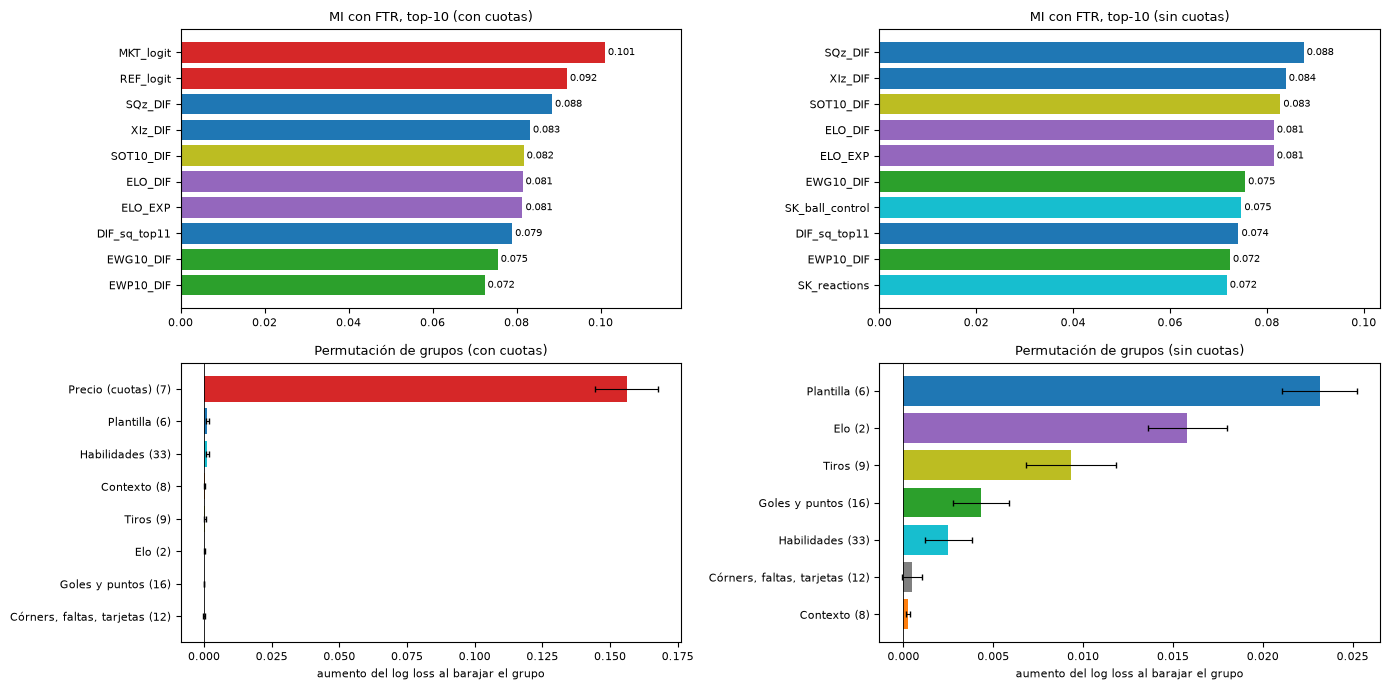

In [9]:
import matplotlib.pyplot as plt
from pathlib import Path
FIGDIR = Path('../../docs/figures'); FIGDIR.mkdir(parents=True, exist_ok=True)
COL_G = {'Precio (cuotas)': 'tab:red', 'Plantilla': 'tab:blue', 'Habilidades': 'tab:cyan', 'Goles y puntos': 'tab:green', 'Tiros': 'tab:olive', 'Elo': 'tab:purple',
         'Córners, faltas, tarjetas': 'tab:gray', 'Contexto': 'tab:orange'}

def fig_mi(ax, esc, k=10, fs_=6.5):
    s_ = MI[esc].head(k)[::-1]
    ax.barh(range(len(s_)), s_.values, color=[COL_G[GRUPO[c]] for c in s_.index]); ax.set_yticks(range(len(s_))); ax.set_yticklabels(s_.index, fontsize=fs_)
    ax.set_title(f'MI con FTR, top-{k} ({esc.lower()})', fontsize=fs_ + 1); ax.tick_params(axis='x', labelsize=fs_)
    for i, v in enumerate(s_.values): ax.text(v, i, f' {v:.3f}', va='center', fontsize=fs_ - 0.5); ax.set_xlim(0, s_.values.max() * 1.18)

def fig_perm(ax, esc, fs_=6.5):
    t_ = res_g[res_g.escenario == esc].sort_values('mean')
    ax.barh(range(len(t_)), t_['mean'], xerr=1.96 * t_['se'], color=[COL_G[g] for g in t_.grupo], capsize=2, error_kw=dict(lw=0.8))
    ax.set_yticks(range(len(t_))); ax.set_yticklabels([f'{g} ({int(n)})' for g, n in zip(t_.grupo, PERM[PERM.escenario == esc].groupby('grupo').n_vars.first().loc[t_.grupo])], fontsize=fs_)
    ax.axvline(0, color='k', lw=0.6); ax.tick_params(axis='x', labelsize=fs_); ax.set_xlabel('aumento del log loss al barajar el grupo', fontsize=fs_)
    ax.set_title(f'Permutación de grupos ({esc.lower()})', fontsize=fs_ + 1)

fig, axs = plt.subplots(2, 2, figsize=(14, 7))
for j, esc in enumerate(ESC): fig_mi(axs[0, j], esc, fs_=8); fig_perm(axs[1, j], esc, fs_=8)
plt.tight_layout(); plt.show()

# versiones de una columna para el informe
for nombre, fn, size in (('imp_mi_paper.png', fig_mi, (3.5, 4.3)), ('imp_perm_paper.png', fig_perm, (3.5, 3.9))):
    f_, a_ = plt.subplots(2, 1, figsize=size)
    for ax_, esc in zip(a_, ESC): fn(ax_, esc)
    plt.tight_layout(); f_.savefig(FIGDIR / nombre, dpi=250); plt.close(f_)

**Qué significa para nuestro caso.** Sin cuotas, el modelo se apoya sobre todo en **la fuerza de largo plazo del equipo** (plantilla y Elo) y en los **tiros a puerta**; la forma de goles de los últimos partidos pesa menos. Con cuotas, el precio ya contiene todo eso y el resto de variables queda en ruido, que es la misma conclusión de la Tabla IV desde otro ángulo. MI y permutación coinciden en el orden, pero solo la permutación mide cuánto depende el modelo de cada grupo; las habilidades tienen MI alta y aporte bajo porque son redundantes con la plantilla.

**Decisión.** Incluir ambas figuras en el informe (Sección VI-F) y reportar los dos rankings con la advertencia de que MI mide dependencia y la permutación mide aporte.

## Resumen de decisiones

| Pregunta | Resultado | Decisión |
|---|---|---|
| ¿Importa el esquema de validación? | K-fold aleatorio y leave-one-season-out dan 0.0002–0.0011 *menos* log loss que el temporal (optimismo leve); mismo orden de modelos | Mantener validación temporal expansiva |
| ¿Qué modelo discrimina mejor (AUC)? | Mercado ≈ LR sobre cuotas (AUC macro 0.684): H 0.73, A 0.74, D 0.59; los demás −0.002 a −0.006; SVM 0.627 | LR sobre cuotas |
| ¿Cómo discrimina el empate? | AUC 0.59, casi nunca se predice (13 de 24,183) | No usar accuracy como métrica principal |
| ¿Quién está mejor calibrado? | LR (ECE 0.007) < HGB < MLP < mercado (0.013) < ALL < XGBoost < SVM (0.022); mismo orden con ECE de ancho y de masa | LR sobre cuotas |
| ¿Por qué falla el SVM? | `P(D)` invertida (AUC 0.44, pendiente −1.6); recalibrado mejora 0.015 pero sigue peor | Documentar como defecto de `SVC(probability=True)` multiclase |
| ¿Se sostienen los IC de `04_modelo.ipynb`? | Bootstrap por bloques: ancho ×1.02; 11/11 contrastes significativos tras BH | Sin cambios; citar el IC por bloques |